# Gresho vortex: velocity error and kinetic-energy loss vs resolution

The Gresho-Chan vortex (Gresho & Chan 1990; Liska & Wendroff 2003) is a steady solution of the
Euler equations: v_phi = 5r (r < 0.2), 2 - 5r (0.2 < r < 0.4), 0 outside, held by a pressure
gradient. Any change is numerical error. Here the registered `Gresho-Vortex-2D` problem runs at
peak Mach 0.1 for t = 1 (about 0.8 turns at the velocity peak) in a periodic unit box, HLLC,
minmod, FP64, at 32², 64², 128² (the CPU ladder of `tests/test_hydro_accuracy_smooth.py`, whose
measured values are printed alongside).

Compared: L1 of |v(t) - v(0)| over the box, and the relative loss of kinetic energy, both against
resolution.

Runtime: about 30 seconds on four CPU cores (an A100 node's CPU cores via SLURM, JAX on the CPU), including JAX start-up and compilation, which dominate.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # this notebook is sized for a CPU; unset it to use a GPU

import contextlib, io, time
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from luna import Config, launch


def run(cfg):
    """launch(cfg), as `python main.py` runs it, with its log kept out of the notebook; (RunResult, wall s)."""
    t0 = time.time()
    with contextlib.redirect_stdout(io.StringIO()):
        res = launch(cfg)
    return res, time.time() - t0


# FP64, PLM, HLLC, quiet: the settings of LUNA's accuracy tests
QUIET = dict(enable_x64=True, ORDER=1, LIMITER=0, riemann_solver="hllc", PLOT_AFTER_SIM=False,
             output_cadence=10**6, diag_interval=10**6, enable_checkpointing=False, clear_output_dir=True)
BASE = replace(Config(), **QUIET)

In [2]:
import glob
from luna.ic_generation import gresho_vortex
from luna.file_io.read_snapshot import read_snapshot

base = replace(BASE, test_problem="Gresho-Vortex-2D", SPATIAL_DIMENSION=2, Lx=1.0, Ly=1.0,
               BOUNDARY=0, gamma=5.0 / 3.0, problem=gresho_vortex.Params(Mmax=0.1),
               t_end=1.0, time_bet_snaps=1.0)
ns, L1, dKE, out = (32, 64, 128), [], [], {}
for n in ns:
    cfg = replace(base, Nx=n, Ny=n, output_dir=f"snapshots/nb07/n{n}")
    res, wall = run(cfg)
    s0 = read_snapshot(sorted(glob.glob(f"{cfg.output_dir}/snapdir_*"))[0])     # t = 0
    U = np.asarray(res.extra["U"], np.float64)
    vx, vy = U[1] / U[0], U[2] / U[0]
    L1.append(float(np.mean(np.hypot(vx - s0["vx"], vy - s0["vy"]))))
    ke0 = 0.5 * np.sum(s0["rho"] * (s0["vx"] ** 2 + s0["vy"] ** 2))
    dKE.append(float(1.0 - 0.5 * np.sum(U[0] * (vx ** 2 + vy ** 2)) / ke0))
    out[n] = (vx, vy)
    print(f"N={n:4d}: {res.n_steps} steps, L1 |v - v0| = {L1[-1]:.4f}, kinetic energy lost {100 * dKE[-1]:.2f} %"
          f"   ({wall:.1f} s)")
o_v = -np.polyfit(np.log(ns), np.log(L1), 1)[0]
o_k = -np.polyfit(np.log(ns), np.log(dKE), 1)[0]
print(f"orders: velocity L1 {o_v:.2f}, kinetic-energy loss {o_k:.2f}")
print("the test measured L1 = 0.138, 0.0538, 0.0229 (order 1.30)")

N=  32: 845 steps, L1 |v - v0| = 0.1381, kinetic energy lost 45.59 %   (4.7 s)


N=  64: 1703 steps, L1 |v - v0| = 0.0538, kinetic energy lost 20.42 %   (5.0 s)


N= 128: 3420 steps, L1 |v - v0| = 0.0229, kinetic energy lost 6.02 %   (11.9 s)
orders: velocity L1 1.30, kinetic-energy loss 1.46
the test measured L1 = 0.138, 0.0538, 0.0229 (order 1.30)


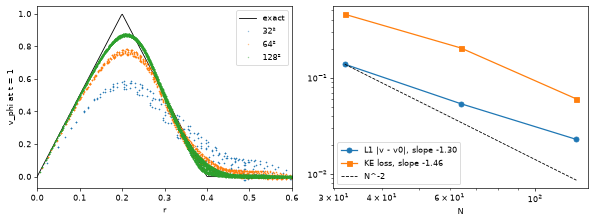

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), dpi=60)
rr = np.linspace(0, 0.6, 300)
ax[0].plot(rr, np.where(rr < 0.2, 5 * rr, np.where(rr < 0.4, 2 - 5 * rr, 0)), "k-", lw=1, label="exact")
for n in ns:
    x = (np.arange(n) + 0.5) / n - 0.5
    X, Y = np.meshgrid(x, x, indexing="ij")
    r = np.hypot(X, Y)
    vphi = (-out[n][0] * Y + out[n][1] * X) / np.maximum(r, 1e-12)
    ax[0].plot(r.ravel(), vphi.ravel(), ".", ms=1.5, alpha=0.4, label=f"{n}²")
ax[0].set_xlim(0, 0.6); ax[0].set_xlabel("r"); ax[0].set_ylabel("v_phi at t = 1"); ax[0].legend()
ax[1].loglog(ns, L1, "o-", label=f"L1 |v - v0|, slope -{o_v:.2f}")
ax[1].loglog(ns, dKE, "s-", label=f"KE loss, slope -{o_k:.2f}")
ax[1].loglog(ns, L1[0] * (ns[0] / np.array(ns)) ** 2, "k--", lw=1, label="N^-2")
ax[1].set_xlabel("N"); ax[1].legend()
fig.tight_layout()

**What this shows.** The velocity error converges at order 1.30, with the test's numbers. The kinetic energy lost by t = 1 is large on coarse grids, 46 %, 20 % and 6 % at 32², 64², 128² (order 1.46): at Mach 0.1 minmod-HLLC is dissipative, and the vortex peak (r = 0.2) spans only 6 cells at 32².

Status (docs/CLAIMS.md): *validated* as part of "second order on smooth flows",
`tests/test_hydro_accuracy_smooth.py:160` (velocity L1 and its order, the angular-momentum loss of
the core); the Liska-Wendroff high-Mach and moving variants are in `tests/test_hydro_hard_lw_gresho.py`.